In [112]:
import os
os.environ['KERAS_BACKEND'] = 'jax'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
import tensorflow as tf

import pickle
import time
import itertools

from scipy.stats import truncnorm 

import bayesflow as bf

In [91]:
# Boundary functions
def fixed_boundary(t, a):
    """Constant decision boundary."""
    return np.full_like(t, a)


def linear_collapse(t, a, k, epsilon=1e-4):
    """Linearly collapsing boundary."""
    return np.maximum(a - k * t, epsilon)


def exponential_collapse(t, a, lam, epsilon=1e-4):
    """Exponentially collapsing boundary."""
    return np.maximum(a * np.exp(-lam * t), epsilon)


def sigmoid_collapse(t, a, k_sig, t_mid, epsilon=1e-4):
    """Sigmoid collapsing boundary."""
    sig = 1.0 / (1.0 + np.exp(-k_sig * (t - t_mid)))
    return np.maximum(a * (1.0 - sig), epsilon)

In [92]:
BOUNDARY_FNS = {
    "fixed": fixed_boundary,
    "linear": linear_collapse,
    "exponential": exponential_collapse,
    "sigmoid": sigmoid_collapse,
}



In [ ]:
MODEL_NAMES = [ "exponential"  ]

DT = 0.002
MAX_TIME = 3.0

FLASH_PAIRS = [
    (0.55, 0.45), (0.60, 0.40), (0.65, 0.35),
    (0.70, 0.30), (0.75, 0.25), (0.80, 0.20),
]


COHERENCES = tuple(round(p1 - p2, 2) for p1, p2 in FLASH_PAIRS)

N_TRIALS_PER_DIFF = 400

DEADLINE_TIME = 1.35

CUE = 0 # 0 speed, 1 Accuracy

HAS_DEADLINE = 1

In [113]:
SHAPE_PRIOR_RANGES = {
    "exponential": ("lam",),
    "sigmoid":     ("k_sig", "t_mid"),
}


In [95]:
# define function for generating priors
def sample_participant_priors(rng):
    """
    Sample participant-specific latent parameters.

    These are assumed to remain constant across all experimental
    conditions for a participant.
    """

    p = {
        "v_scale": truncnorm.rvs(0, np.inf, loc=1.25, scale=0.75, random_state=rng),
        # "t0": rng.uniform(0, 0.40),
        "t0": truncnorm.rvs(0, np.inf, loc=0.19, scale=0.138, random_state=rng),
        # "sv": truncnorm.rvs(0, np.inf, loc=0.10, scale=0.05, random_state=rng), # maybbe  we dont require sv at all.
        "a_base": rng.uniform(0, 1),
        "lam": truncnorm.rvs(0, np.inf, loc=1.5, scale=1, random_state=rng),
        "k_sig": truncnorm.rvs(0, np.inf, loc=1.5, scale=1, random_state=rng),
        "t_mid": truncnorm.rvs(0, np.inf, loc=0.5, scale=0.25, random_state=rng),
    }
    return p


In [ ]:
# Trial-level DDM simulation

def simulate_ddm_batch(
    v,
    a,
    t0,
    z,
    boundary,
    dt,
    n_trials,
    deadline_step,
    noise_sd,
    rng,
):
    """
    Simulate multiple DDM trials using Euler-Maruyama integration.

    Parameters
    ----------
    v : float
        Mean drift rate.

    a : float
        Initial boundary separation.

    t0 : float
        Non-decision time.

    z : float
        Relative starting point (0.5 = unbiased).


    boundary : ndarray
        Boundary height at every time step.

    Returns
    -------
    rts : ndarray
        Reaction times (NaN = non-response)

    choices : ndarray
        1 = upper boundary
        0 = lower boundary
       -1 = deadline reached
    """

    # Trial-specific drift rates
    
    v_trial = np.broadcast_to(np.asarray(v, dtype=float), (n_trials,)).copy()

    # Starting point
    x = np.full(
        n_trials,
        (z - 0.5) * 2 * a,
        dtype=float,
    )

    rts = np.full(n_trials, np.nan)
    choices = np.full(n_trials, -1, dtype=int)

    active = np.ones(n_trials, dtype=bool)

    max_steps = len(boundary)

    if deadline_step is not None:
        max_steps = min(max_steps, deadline_step)

    for step in range(max_steps):

        if not active.any():
            break

        b = boundary[step]

        upper_hit = active & (x >= b)
        lower_hit = active & (x <= -b)

        rts[upper_hit] = t0 + step * dt
        choices[upper_hit] = 1

        rts[lower_hit] = t0 + step * dt
        choices[lower_hit] = 0

        active &= ~(upper_hit | lower_hit)

        if active.any():
            x[active] += (
                v_trial[active] * dt
                + noise_sd
                * np.sqrt(dt)
                * rng.standard_normal(active.sum())
            )

    return rts, choices

In [97]:
COHERENCES

(0.1, 0.2, 0.3, 0.4, 0.5, 0.6)

In [ ]:

# Simulate one experimental condition

def simulate_cell(
    params,
    model,
    coherences,
    n_trials_per_diff,
    dt,
    max_time,
    deadline_time=None,
    z=0.5,
    noise_sd=0.1,
    rng=None,
   
):
    """
    Simulate one participant under one experimental condition.

    The boundary is shared across all coherence levels.
    Only the drift rate changes with coherence.

    Parameters
    ----------
    params : dict
        Output of apply_condition_effects().

    model : str
        Boundary model.

    coherences : iterable
        Stimulus coherence values.

    Returns
    -------
    rts
    choices
    coherence_values
    difficulty_indices
    """

    if rng is None:
        rng = np.random.default_rng()



    time_axis = np.arange(int(max_time / dt)) * dt

    boundary_fn = BOUNDARY_FNS[model]

    a_base =  params["a_base"]      
    shape_kwargs = {n: params[n] for n in SHAPE_PRIOR_RANGES[model]}
    boundary = boundary_fn(time_axis, a=a_base, **shape_kwargs)

    deadline_step = None

    if deadline_time is not None:
        deadline_step = int(deadline_time / dt)


    # Simulate every coherence level
    all_rts = []
    all_choices = []
    all_coherences = []
    all_difficulties = []
    all_pairs = []

   
    pairs_to_run = list(zip(coherences, FLASH_PAIRS))
    start = 0                                 

    for difficulty_idx, (coherence, pair) in enumerate(pairs_to_run, start=start):

        drift = params["v_scale"] * coherence

        rts, choices = simulate_ddm_batch(
            v=drift,
            a=params["a_base"],
            t0=params["t0"],
            z=z,
            boundary=boundary,
            dt=dt,
            n_trials=n_trials_per_diff,
            deadline_step=deadline_step,
            noise_sd=noise_sd,
            rng=rng,
        )

        all_rts.append(rts)
        all_choices.append(choices)

        all_coherences.append(
            np.full(n_trials_per_diff, coherence)
        )
        all_pairs.append([list(pair)] * n_trials_per_diff)


        all_difficulties.append(
            np.full(
                n_trials_per_diff,
                difficulty_idx,
                dtype=int,
            )
        )

    return (
        np.concatenate(all_rts),
        np.concatenate(all_choices),
    np.concatenate(all_coherences),
        list(itertools.chain.from_iterable(all_pairs)),
        np.concatenate(all_difficulties),
    )

In [99]:
def simulate_full_dataset(model="exponential", n_participants=24,
                          coherences=COHERENCES, n_trials_per_cell=400,
                          dt=DT, deadline_time=DEADLINE_TIME,
                          max_time=MAX_TIME, noise_sd=0.1, seed=0):
    rng = np.random.default_rng(seed)
    rows, true_params = [], []

    for pp in range(1, n_participants + 1):
        params = sample_participant_priors(rng)
        params["difficulty_idx"] = (pp - 1) % len(FLASH_PAIRS)

        rts, choices, cohs, pairs, diffs = simulate_cell(
            params=params, model=model, coherences=coherences,
            n_trials_per_diff=n_trials_per_cell, dt=dt, max_time=max_time,
            deadline_time=deadline_time, noise_sd=noise_sd, rng=rng,
        )

        for rt, ch, co, pr, d in zip(rts, choices, cohs, pairs, diffs):
            rows.append({
                "pp": pp, "cue": CUE, "has_deadline": HAS_DEADLINE,
                "coherence": co, "pair": pr, "difficulty": d,
                "rt": rt,
                "acc": np.nan if ch == -1 else int(ch == 1),
                "nonresp_reason": "hit_deadline" if ch == -1 else None,
            })

        true_params.append({"pp": pp, "cue": CUE,
                            "has_deadline": HAS_DEADLINE,
                            "model": model, **params})

    return pd.DataFrame(rows), pd.DataFrame(true_params)

In [100]:
def prior():
    """
    BayesFlow prior.

    Samples ONE participant together with a boundary model.

    The experimental manipulations (cue and deadline)
    are deterministic and are applied later inside the
    likelihood.
    """

    rng = np.random.default_rng()

    model_idx = rng.integers(len(MODEL_NAMES))

    participant = sample_participant_priors(rng)

    return {
        "model_idx": model_idx,
        **participant,
    }

In [101]:
def likelihood(model_idx, v_scale, t0,  a_base,
                lam, k_sig, t_mid):
    rng = np.random.default_rng()
    model = MODEL_NAMES[int(model_idx)]

    params = {"v_scale": v_scale, "t0": t0, 
              "a_base": a_base,
               "lam": lam, "k_sig": k_sig, "t_mid": t_mid}

    rts, choices, coh, _, _ = simulate_cell(
        params=params, model=model, coherences=COHERENCES,
        n_trials_per_diff=N_TRIALS_PER_DIFF, dt=DT, max_time=MAX_TIME,
        deadline_time=DEADLINE_TIME, rng=rng,
    )

    return {
        "rt":        np.where(choices == -1, -1.0, rts).astype(np.float32),
        "choice":    choices.astype(np.float32),
        "coherence": coh.astype(np.float32),
    }

In [102]:
def _defective_cdf(rts, correct_mask, n_total):
    rt_c = rts[correct_mask].dropna()
    rt_e = rts[~correct_mask & rts.notna()].dropna()
    p_c, p_e = len(rt_c) / n_total, len(rt_e) / n_total
    x_c, y_c = np.sort(rt_c), np.arange(1, len(rt_c) + 1) / max(len(rt_c), 1) * p_c
    x_e, y_e = np.sort(rt_e), np.arange(1, len(rt_e) + 1) / max(len(rt_e), 1) * p_e
    return (x_c, y_c), (x_e, y_e)


def plot_insight_summary(df, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    psy = df.groupby("coherence").agg(acc=("acc", "mean"),
                                      n_pp=("pp", "nunique")).reset_index()
    axes[0].plot(psy.coherence, psy.acc, "o-", color="#d95f02")
    axes[0].set(xlabel="Coherence", ylabel="Accuracy", ylim=(0, 1),
                title="Psychometric")

    chr_ = df.groupby("coherence").agg(rt=("rt", "mean")).reset_index()
    axes[1].plot(chr_.coherence, chr_.rt, "o-", color="#1b9e77")
    axes[1].set(xlabel="Coherence", ylabel="Mean RT (s)", title="Chronometric")

    (xc, yc), (xe, ye) = _defective_cdf(df["rt"], df["acc"] == 1, len(df))
    axes[2].plot(xc, yc, color="steelblue", label="correct")
    axes[2].plot(xe, ye, color="steelblue", ls="--", label="error")
    axes[2].axvline(DEADLINE_TIME, color="k", ls=":", lw=1, label="deadline")
    axes[2].set(xlabel="RT (s)", ylabel="Defective CDF", title="Slow-error signature")
    axes[2].legend(fontsize=7)

    plt.suptitle(title or "Simulated SAT data (speed cue, deadline)")
    plt.tight_layout(); plt.show()

def plot_difficulty_assignment(df):
    """Shows which participant was locked to which coherence/difficulty."""
    assign = df.groupby("pp").agg(coherence=("coherence", "first")).reset_index()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(assign["pp"], assign["coherence"], s=60, color="#377eb8")
    ax.set_xlabel("Participant (pp)"); ax.set_ylabel("Assigned coherence")
    ax.set_title("Fixed difficulty per participant")
    ax.set_xticks(assign["pp"])
    plt.tight_layout(); plt.show()

Boundary shape: [1.44159613e-01 1.43168754e-01 1.42184705e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.03228387 0.03218601 0.03208844 ... 0.00034289 0.00034185 0.00034081]
Boundary shape: [3.98672824e-01 3.96324221e-01 3.93989453e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.83988255 0.83618169 0.83249715 ... 0.00113011 0.00112513 0.00112017]
Boundary shape: [0.64302345 0.64082353 0.63863114 ... 0.00380324 0.00379022 0.00377726]
Boundary shape: [0.46979967 0.46824748 0.46670043 ... 0.00331392 0.00330297 0.00329206]
Boundary shape: [6.29074519e-01 6.25390167e-01 6.21727393e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.6020548  0.59997069 0.59789379 ... 0.00335094 0.00333934 0.00332778]
Boundary shape: [0.53046643 0.52862093 0.52678186 ... 0.00287658 0.00286657 0.0028566 ]
Boundary shape: [0.80992009 0.80698659 0.80406371 ... 0.00354315 0.00353031 0.00351753]
Boundary shape: [0.00048806 0.00048524 0.0004

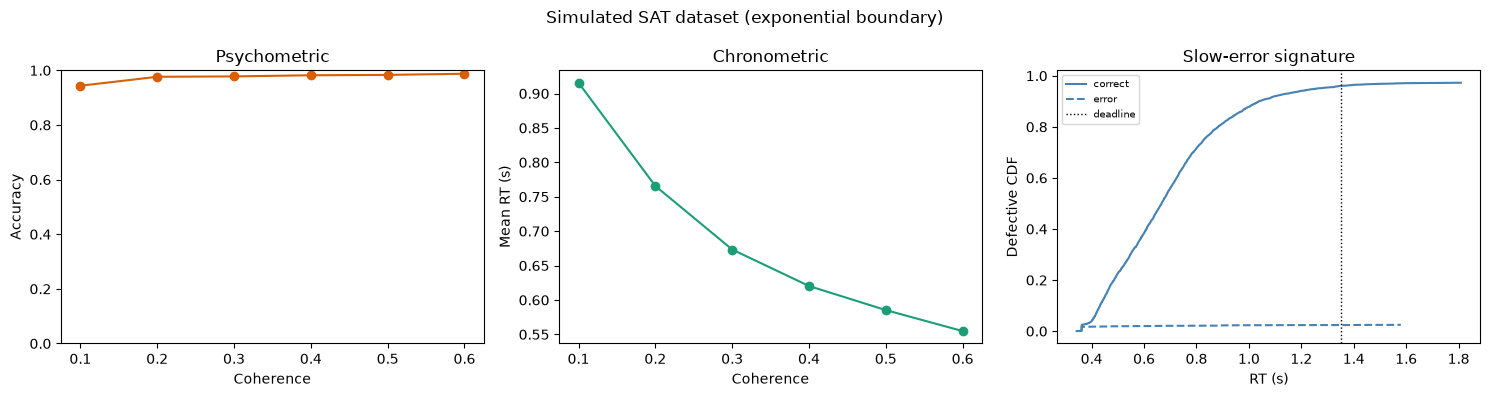

In [103]:
import os
os.makedirs("../data", exist_ok=True)

true_params = []
for model in ["exponential"]:
    df, params_df = simulate_full_dataset(model=model, n_participants=24, n_trials_per_cell=30, seed=1)
    df.to_csv(f"../data/simulated_data_{model}.csv", index=False)
    params_df["model"] = model
    true_params.append(params_df)

    if model == "exponential":
        plot_insight_summary(df, title=f"Simulated SAT dataset ({model} boundary)")

true_params_df = pd.concat(true_params, ignore_index=True)
true_params_df.to_csv("../data/true_params.csv", index=False)


In [104]:
simulator = bf.make_simulator([prior, likelihood])

sim_draws = simulator.sample(50)

Boundary shape: [0.59639177 0.59423622 0.59208846 ... 0.00263915 0.00262961 0.00262011]
Boundary shape: [5.54857060e-01 5.52175896e-01 5.49507689e-01 ... 3.93536695e-04
 3.91635059e-04 3.89742612e-04]
Boundary shape: [0.21882374 0.21800385 0.21718703 ... 0.00079355 0.00079058 0.00078762]
Boundary shape: [0.68093044 0.67783987 0.67476333 ... 0.00075088 0.00074747 0.00074408]
Boundary shape: [4.30480311e-01 4.28403815e-01 4.26337336e-01 ... 3.09249709e-04
 3.07757990e-04 3.06273466e-04]
Boundary shape: [0.21526785 0.21437375 0.21348337 ... 0.0004237  0.00042194 0.00042019]
Boundary shape: [0.17820837 0.17746549 0.17672571 ... 0.00034285 0.00034142 0.00033999]
Boundary shape: [1.95690858e-01 1.94791004e-01 1.93895289e-01 ... 1.97294735e-04
 1.96387506e-04 1.95484450e-04]
Boundary shape: [0.90082319 0.89716559 0.89352285 ... 0.00203947 0.00203119 0.00202294]
Boundary shape: [0.6106551  0.60814931 0.6056538  ... 0.00129568 0.00129036 0.00128507]
Boundary shape: [0.79719224 0.79401487 0.7908

In [105]:
par_keys = [
    "a_base",
    "v_scale",
    "t0",
    
]
par_names = [r"$a_\text{base}$", r"$v_\text{scale}$", r"$t_0$",]

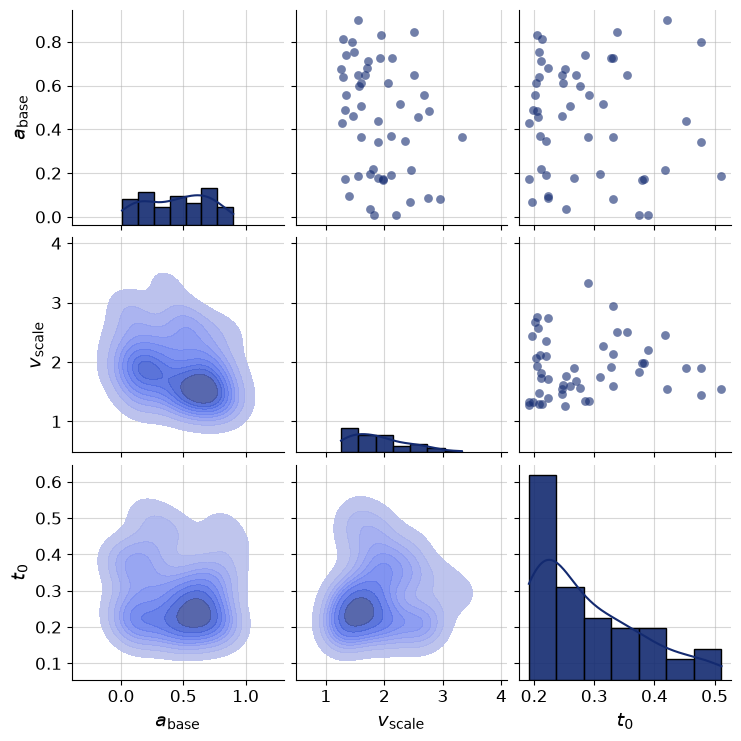

In [106]:
f = bf.diagnostics.plots.pairs_samples(
    samples=sim_draws,
    variable_keys=par_keys,
    variable_names=par_names
)

In [ ]:
# 4 Parameter: v_scale, t0, a, lam
num_params = 4

inference_network = bf.networks.CouplingFlow(
    num_params=num_params,
    num_coupling_layers=4,
    coupling_design="interleaved"
)

In [114]:
@keras.saving.register_keras_serializable()
def stack_trials_for_deepset(data, **kwargs):
    # If the required keys are not present, return data as is.
    # This handles cases where data is already processed or in inverse mode.
    if 'rt' not in data or 'choice' not in data or 'coherence' not in data:
        return data

    # Stack rt, choice, and coherence along a new axis to create a 2D array
    # Each row will be a trial, and columns will be its features (rt, choice, coherence)
    stacked_data = tf.stack([data['rt'], data['choice'], data['coherence']], axis=-1)

    # Create a new dictionary from the input data, keeping all original keys
    # and adding 'summary_variables'. Explicitly remove the original
    # 'rt', 'choice', 'coherence' as they are now combined.
    output_data = {k: v for k, v in data.items() if k not in ['rt', 'choice', 'coherence']}
    output_data['summary_variables'] = stacked_data
    return output_data

adapter = (
    bf.adapters.Adapter()
    .to_array()
    .convert_dtype("float64", "float32")
    .concatenate(["v_scale", "t0", "a_base","lam"], into="inference_variables")
    .add_transform(stack_trials_for_deepset)
    .keep(["inference_variables", "summary_variables"])
)

In [ ]:
 # coherence is present in the summary variables, so its going in the network. ( check with paula)
sample = simulator.sample(batch_shape=(4,))
adapted = adapter(sample)
sv = adapted["summary_variables"]
print(sv.shape)                     
print(np.unique(sv[0, :, 2]))       

Boundary shape: [0.82379662 0.8203703  0.81695823 ... 0.00160744 0.00160076 0.0015941 ]
Boundary shape: [0.4083242  0.40670492 0.40509206 ... 0.00106573 0.0010615  0.00105729]
Boundary shape: [0.68080815 0.6778633  0.6749312  ... 0.00103453 0.00103005 0.0010256 ]
Boundary shape: [0.77897821 0.77635956 0.77374971 ... 0.00503857 0.00502163 0.00500475]
(4, 2400, 3)
[0.1 0.2 0.3 0.4 0.5 0.6]


In [109]:

CHECKPOINT_DIR = os.path.join("checkpoints", "ddm_sbi_run")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs("./networks", exist_ok=True) 

workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=bf.networks.SetTransformer(),
    checkpoint_filepath=CHECKPOINT_DIR,
    checkpoint_name="ddm_workflow",
)


Existing checkpoints are not automatically loaded. Upon refitting, the checkpoints will be overwritten.
To load the stored approximator from the checkpoint, use approximator = keras.saving.load_model("checkpoints/ddm_sbi_run/ddm_workflow.keras")


In [110]:
sample = simulator.sample(batch_shape=(8,))

Boundary shape: [0.65938463 0.65683801 0.65430122 ... 0.00201077 0.00200301 0.00199527]
Boundary shape: [4.97887779e-01 4.94140754e-01 4.90421929e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.74106628 0.73829998 0.735544   ... 0.0027443  0.00273405 0.00272385]
Boundary shape: [0.03519203 0.03498289 0.03477499 ... 0.0001     0.0001     0.0001    ]
Boundary shape: [3.58073398e-01 3.55875890e-01 3.53691868e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.55257991 0.5504373  0.54830299 ... 0.00164663 0.00164024 0.00163388]
Boundary shape: [1.71372617e-01 1.70440975e-01 1.69514397e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.67683148 0.674022   0.67122417 ... 0.00133714 0.00133159 0.00132606]


In [111]:
EPOCHS = 5
BATCH_SIZE = 10
history = workflow.fit_online(epochs=EPOCHS, batch_size=BATCH_SIZE, num_batches_per_epoch=10)


history_path = f"./networks/bayesflow_history_{int(time.time())}_epoch_{EPOCHS}.pkl"
tmp_path = history_path + ".tmp"
with open(tmp_path, "wb") as f:
    pickle.dump(history, f)
os.replace(tmp_path, history_path)

print(f"History saved successfully to {history_path}!")
print(f"Model weights were checkpointed automatically to {CHECKPOINT_DIR}/")


INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


Boundary shape: [7.62177123e-01 7.57958174e-01 7.53762579e-01 ... 1.87622740e-04
 1.86584175e-04 1.85551358e-04]
Boundary shape: [0.60497021 0.60265912 0.60035685 ... 0.00196485 0.00195735 0.00194987]
Boundary shape: [1.56438355e-01 1.55611534e-01 1.54789084e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [7.08273705e-01 7.03954559e-01 6.99661753e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.81331014 0.81086043 0.8084181  ... 0.00889338 0.0088666  0.00883989]
Boundary shape: [1.80901036e-01 1.79910189e-01 1.78924769e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [9.38569143e-01 9.33467381e-01 9.28393350e-01 ... 2.68459862e-04
 2.67000600e-04 2.65549270e-04]
Boundary shape: [2.12204856e-01 2.11018169e-01 2.09838119e-01 ... 1.00000000e-04
 1.00000000e-04 1.00000000e-04]
Boundary shape: [0.14725316 0.14663787 0.14602516 ... 0.00027914 0.00027797 0.00027681]
Boundary shape: [1.05839028e-01 1.05109873e-01 1.04385742e

INFO:bayesflow:Training completed in 4.51 minutes.
INFO:bayesflow:Training is now finished.
You can find the trained approximator at 'checkpoints/ddm_sbi_run/ddm_workflow.keras'.
To load it, use approximator = keras.saving.load_model("checkpoints/ddm_sbi_run/ddm_workflow.keras").


History saved successfully to ./networks/bayesflow_history_1786900674_epoch_5.pkl!
Model weights were checkpointed automatically to checkpoints/ddm_sbi_run/


In [ ]:

# history_path = "C:/Users/paula/DATEN/UNI/Job/Pauly/03_Sandwich/SBI---Project/models/networks/bayesflow_history_1784482464_epoch_30.pkl"

if os.path.exists(history_path) and os.path.getsize(history_path) > 0:
    with open(history_path, "rb") as f:
        history = pickle.load(f)
else:
    raise FileNotFoundError(
        f"{history_path} is missing or empty - re-run the training cell above "
        "before continuing."
    )

# If you're continuing in a NEW session (kernel restarted after training),
# reload the actual trained weights here instead of relying on `workflow`,
# which would otherwise be an untrained, freshly-initialized object:
#
approximator = keras.saving.load_model(os.path.join(CHECKPOINT_DIR, "ddm_workflow.keras"))
#
# and then sample from `approximator` instead of `workflow` below.


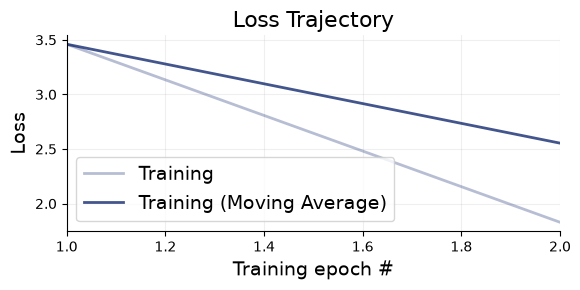

In [ ]:
f  = bf.diagnostics.loss(history, figsize=(6,3))

In [ ]:
test_data = workflow.simulate(100)

# Pass the RAW simulated data straight to workflow.sample() - it applies the
# adapter internally. Applying `adapter(...)` manually beforehand (as before)
# caused a double-adaptation and the "strict=False before strict=True" error.
samples = approximator.sample(num_samples=1000, conditions=test_data)


Sampling: 100%|██████████| 1/1 [00:00<00:00,  1.53batch/s]


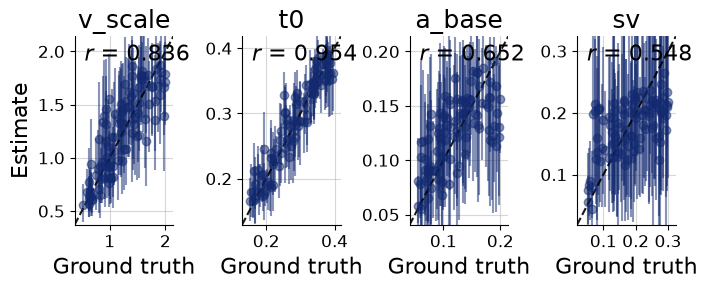

In [ ]:
f2 = bf.diagnostics.recovery(samples, test_data, figsize=(7, 3))

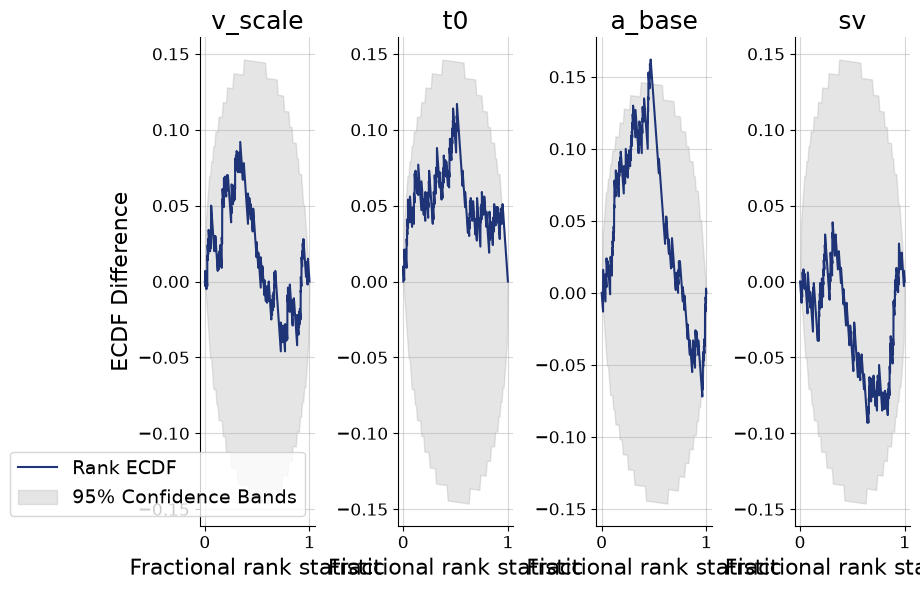

In [ ]:
f3 = bf.diagnostics.calibration_ecdf(samples, test_data, figsize=(9, 6))

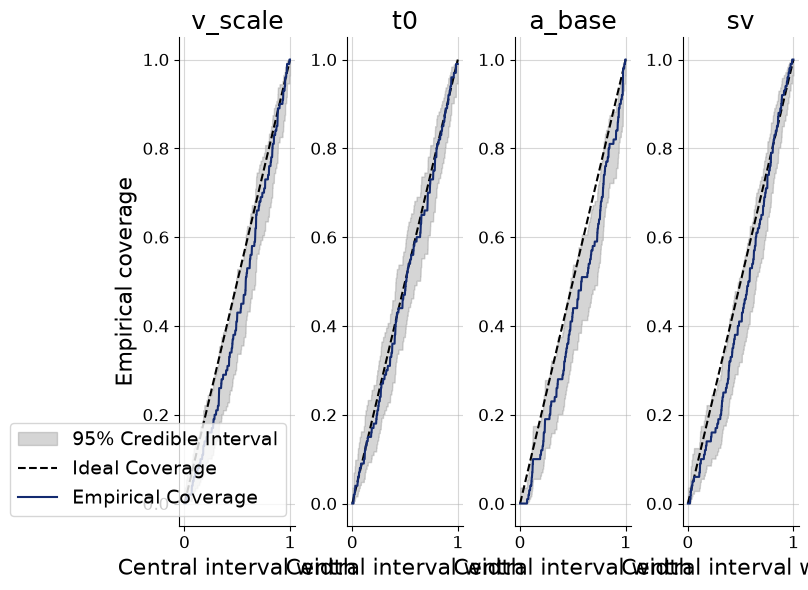

In [ ]:
f4 = bf.diagnostics.coverage(samples, test_data, figsize=(8, 6))


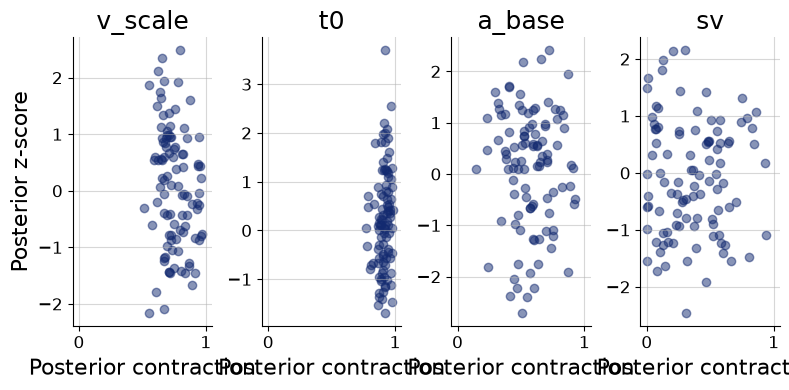

In [ ]:
# Posterior contraction
f5 = bf.diagnostics.z_score_contraction(samples, test_data, figsize=(8, 4))


In [ ]:
empirical_data = pd.read_csv("../data/Katsimposis/experiment-2-Flash.csv")
empirical_data["difficulty"].unique()

empirical_data = empirical_data[
    (empirical_data["cue"] == 0) & (empirical_data["deadline"] == 1)
].reset_index(drop=True)
print(empirical_data.shape, empirical_data["difficulty"].unique())

(0, 7) <StringArray>
[]
Length: 0, dtype: str


In [ ]:
# Katsimpokis dataset
# Draw 1000 posterior samples for each participant in the dataset


mapping_diff = {
    "[0.55, 0.45]": 0.1,
    "[0.6, 0.4]": 0.2,
    "[0.65, 0.35]": 0.3,
    "[0.7, 0.3]": 0.4,
    "[0.75,0.25]": 0.5,
    "[0.8,0.2]": 0.6
}
empirical_data['difficulty'] = empirical_data["difficulty"].replace(mapping_diff)

mapping_deadline = {
    "Deadline": 1,
    "No Deadline": 0
}
empirical_data["has_deadline"] = empirical_data["deadline"].replace(mapping_deadline)
empirical_data["deadline"] = empirical_data["deadline"].replace(mapping_deadline)

mapping_cue = {
    "AC":1,
    "SP":0
}
empirical_data["cue"] = empirical_data["cue"].replace(mapping_cue)




In [ ]:
df = empirical_data
# 1. Daten als reine 1D-NumPy-Arrays aus dem DataFrame extrahieren
# (Stelle sicher, dass 'choice', 'cue' und 'has_deadline' bereits reine Zahlen wie 0.0 oder 1.0 sind!)
rt_array = df['rt'].to_numpy(dtype=np.float64)
choice_array = df['acc'].to_numpy(dtype=np.float64)
coherence_array = df['difficulty'].to_numpy(dtype=np.float64)

# Für die Bedingungen (Conditions)
cue_array = df['cue'].to_numpy(dtype=np.float64)
deadline_array = df['has_deadline'].to_numpy(dtype=np.float64)

# 2. Batch-Dimension hinzufügen (Form von [Trials] zu [1, Trials] ändern)
# Das ist zwingend notwendig, da BayesFlow dreidimensionale Batches erwartet!
empirical_data_prep = {
    "rt": rt_array[np.newaxis, :],
    "choice": choice_array[np.newaxis, :],
    "coherence": coherence_array[np.newaxis, :],
    "cue": cue_array[np.newaxis, :],
    "has_deadline": deadline_array[np.newaxis, :]
}


In [ ]:


# 1. Deine extrahierten 1D-Arrays aus dem DataFrame (wie gehabt)
rt_array = df['rt'].to_numpy(dtype=np.float64)
choice_array = df['acc'].to_numpy(dtype=np.float64)
coherence_array = df['difficulty'].to_numpy(dtype=np.float64)
cue_array = df['cue'].to_numpy(dtype=np.float64)
deadline_array = df['has_deadline'].to_numpy(dtype=np.float64)

# 2. Definiere eine verträgliche Chunk-Größe (z. B. 200 Trials pro Block)
# So bleibt die Attention-Matrix handhabbar (200x200 statt 19033x19033)
chunk_size = 400  
num_trials = len(rt_array)

all_samples = []

# Schleife über die Daten in kleinen Schritten
for i in range(0, num_trials, chunk_size):
    # Slice die Daten für den aktuellen Block
    rt_chunk = rt_array[i:i+chunk_size]
    choice_chunk = choice_array[i:i+chunk_size]
    coherence_chunk = coherence_array[i:i+chunk_size]
    cue_chunk = cue_array[i:i+chunk_size]
    deadline_chunk = deadline_array[i:i+chunk_size]
    
    # Überspringe den letzten Block, falls er winzig klein sein sollte
    if len(rt_chunk) < 10:
        continue
        
    # Baue das Mini-Batch-Dictionary mit führender Batch-Dimension (1, chunk_size)
    chunk_data = {
        "rt": rt_chunk[np.newaxis, :],
        "choice": choice_chunk[np.newaxis, :],
        "coherence": coherence_chunk[np.newaxis, :],
        "cue": cue_chunk[np.newaxis, :],
        "has_deadline": deadline_chunk[np.newaxis, :]
    }
    
    # Inferenz für diesen Chunk ausführen
    try:
        chunk_samples = approximator.sample(
            num_samples=1000, 
            conditions=chunk_data
        )
        # Extrahiere die geschätzten Parameter (passe den Key ggf. an deinen Output an)
        # Meistens liegen sie in 'parameters' oder direkt als Array im Dictionary
        if 'parameters' in chunk_samples:
            all_samples.append(chunk_samples['parameters'])
        else:
            # Falls BayesFlow das Ergebnis direkt flach ausgibt, nehmen wir den ersten Key
            first_key = list(chunk_samples.keys())[0]
            all_samples.append(chunk_samples[first_key])
            
    except Exception as e:
        # print(f"Fehler bei Chunk ab Index {i}: {e}")
        continue

# 3. Aggregation aller Chunks zu einem finalen Parameter-Set
# Wir mitteln die Posteriors über die verschiedenen Datenblöcke
if len(all_samples) > 0:
    all_samples = np.concatenate(all_samples, axis=0) # Form: (Anzahl_Chunks * 1000, Parameter_Dim)

# Der finale "beste" Parametervektor für die Katsimpokis-Daten:
final_parameter_estimates = np.mean(all_samples, axis=0)

print("Erfolgreich geschätzte Parameter-Mittelwerte:")
print(final_parameter_estimates)

Erfolgreich geschätzte Parameter-Mittelwerte:
nan


/Users/dmahima/Documents/Data Science/sbi/SBI_Project/venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/dmahima/Documents/Data Science/sbi/SBI_Project/venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:

def resimulate_from_posterior(posterior_draws, model="exponential",
                              difficulty_idx=0, n_resim=100, seed=None,
                              shape_kwargs=None):
    rng = np.random.default_rng(seed)
    shape_kwargs = shape_kwargs or {"k": 0.1, "lam": 1.0, "k_sig": 5.0, "t_mid": 0.8}
    idxs = rng.choice(len(posterior_draws),
                      size=min(n_resim, len(posterior_draws)), replace=False)
    out = []
    for i in idxs:
        v_scale_i, t0_i, a_base_i = posterior_draws[i, :4]
        out.append(likelihood(
            model_idx=MODEL_NAMES.index(model),
            v_scale=v_scale_i, t0=t0_i, a_base=a_base_i,
            **shape_kwargs
        ))
    return out

# Beispielaufruf mit deinen gepoolten Chunk-Samples:
resim_datasets = resimulate_from_posterior(all_samples, model="exponential", n_resim=100)

In [ ]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (choice: 0/1, NaN = non-response bereits vorher rausgefiltert oder rausfiltern)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend() 
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt["has_deadline"]==1, bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt["has_deadline"]==0, bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all["has_deadline"]==1, bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all["has_deadline"]==0, bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())

In [ ]:

# --- Empirische Daten nach Deadline aufteilen ---
if len(resim_datasets)>0:
    emp_deadline_mask = df["has_deadline"].to_numpy() == 1
    emp_rt_dl = emp_rt[valid_emp & emp_deadline_mask[valid_emp]] if emp_deadline_mask.shape == valid_emp.shape else None

    # Sauberer: direkt aus df neu extrahieren, mit has_deadline mit im gleichen Filter
    mask_valid = ~df["acc"].isna()
    emp_rt_full = df["rt"].to_numpy(dtype=np.float64)
    emp_hd_full = df["has_deadline"].to_numpy(dtype=np.float64)

    emp_rt_dl1 = emp_rt_full[mask_valid & (emp_hd_full == 1)]
    emp_rt_dl0 = emp_rt_full[mask_valid & (emp_hd_full == 0)]

    # --- Simulierte Daten nach Deadline aufteilen ---
    resim_rt_dl1 = np.concatenate([
        d["rt"][(d["choice"] != -1) & (d["has_deadline"] == 1)] for d in resim_datasets
    ])
    resim_rt_dl0 = np.concatenate([
        d["rt"][(d["choice"] != -1) & (d["has_deadline"] == 0)] for d in resim_datasets
    ])

    # --- Plot: zwei Panels nebeneinander ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    axes[0].hist(emp_rt_dl1, bins=50, density=True, alpha=0.5, label="Empirisch", color="steelblue")
    axes[0].hist(resim_rt_dl1, bins=50, density=True, alpha=0.5, label="Simuliert", color="darkorange")
    axes[0].set_title("Deadline")
    axes[0].set_xlabel("Reaction Time (s)")
    axes[0].set_ylabel("Density")
    axes[0].legend()

    axes[1].hist(emp_rt_dl0, bins=50, density=True, alpha=0.5, label="Empirisch", color="steelblue")
    axes[1].hist(resim_rt_dl0, bins=50, density=True, alpha=0.5, label="Simuliert", color="darkorange")
    axes[1].set_title("No Deadline")
    axes[1].set_xlabel("Reaction Time (s)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def prior_predictive_check(n_draws=200, model_fixed=None, seed=None):
    """
    Zieht n_draws Parametersätze direkt aus deinem prior() und simuliert
    mit likelihood() -- ganz ohne BayesFlow/Posterior dazwischen.

    model_fixed: falls gesetzt (z.B. "exponential"), wird immer dieses
                 Modell simuliert statt zufällig aus prior() zu übernehmen.
                 Sinnvoll, um Modell-Unsicherheit vom Parameter-Unsicherheit
                 zu trennen.
    """
    rng = np.random.default_rng(seed)
    datasets = []

    for _ in range(n_draws):
        p = prior()  # zieht model_idx + v_scale, t0, sv, a_base aus deinen Prior-Ranges

        model_idx = MODEL_NAMES.index(model_fixed) if model_fixed is not None else p["model_idx"]

        data = likelihood(
            model_idx=model_idx,
            v_scale=p["v_scale"],
            t0=p["t0"],
    
            a_base=p["a_base"],
           
            lam=p.get("lam", 1.0),
            k_sig=p.get("k_sig", 5.0),
            t_mid=p.get("t_mid", 0.8)
        )
        datasets.append(data)

    return datasets

# --- Prior-Predictive-Draws erzeugen ---
if len(resim_datasets) > 0:
    prior_pred_datasets = prior_predictive_check(n_draws=200, model_fixed="exponential", seed=0)

    prior_pred_rt = np.concatenate([
        d["rt"][d["choice"] != -1] for d in prior_pred_datasets
    ])

    # --- Vergleich: Empirisch vs. Prior-Predictive (KEIN Posterior-Fit involviert) ---
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirisch", color="steelblue")
    ax.hist(prior_pred_rt, bins=60, density=True, alpha=0.5, label="Prior Predictive", color="mediumseagreen")
    ax.set_xlabel("Reaction Time (s)")
    ax.set_ylabel("Density")
    ax.set_title("Prior Predictive Check: liegt der empirische Bereich überhaupt im Prior-Support?")
    ax.legend()
    plt.show()

    print("Empirischer Median RT:", np.median(emp_rt))
    print("Prior-Predictive Median RT:", np.median(prior_pred_rt))
    print("Empirisches 10%/90%-Quantil:", np.quantile(emp_rt, [0.1, 0.9]))
    print("Prior-Predictive 10%/90%-Quantil:", np.quantile(prior_pred_rt, [0.1, 0.9]))

In [ ]:
# Test: Trainiere/simuliere Testdaten mit GENAU der Trial-Anzahl,
# die du auch bei der echten Anwendung nutzt (z.B. 400 statt 20 pro Cell)
# und schau, ob die Recovery dann noch genauso gut aussieht wie bei
# den ursprünglichen Trainings-Batch-Größen.

test_data_large = workflow.simulate(20)  # gleiche Anzahl Sets wie sonst
# aber: passe n_trials_per_diff / Trial-Struktur so an, dass sie der
# Chunk-Größe entspricht, die du bei den echten Daten nutzt

In [ ]:
print(test_data_large)

{'model_idx': array([[0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [3],
       [0],
       [2],
       [1],
       [2],
       [0],
       [3],
       [0],
       [3],
       [1],
       [3],
       [3],
       [0],
       [2]]), 'v_scale': array([[1.01522489],
       [1.39578148],
       [0.77586506],
       [1.03390891],
       [1.71399404],
       [0.57513226],
       [1.99894792],
       [0.64713716],
       [1.78519013],
       [1.05893917],
       [0.93406058],
       [0.67092577],
       [1.613685  ],
       [0.6810139 ],
       [1.43255456],
       [1.71441814],
       [1.39704848],
       [1.12758013],
       [1.04631264],
       [0.90937747]]), 't0': array([[0.19982256],
       [0.19924782],
       [0.30884405],
       [0.1756941 ],
       [0.20032115],
       [0.15170568],
       [0.19645881],
       [0.23150553],
       [0.27888427],
       [0.32982353],
       [0.20109387],
       [0.28246699],
       [0.15071705],
       [0.28733496],
       [0.3